# 00 · 环境检查与第一个量子程序

对应讲义第 03 部分 · 约 5 分钟 · 建议课前完成

依次运行下面的单元格（`Shift + Enter`）。看到「✅ 环境就绪」和 Bell 态的采样结果，就可以开始上课了。

## 1. 检查环境

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import mqlab

mqlab.check_env()

Python            3.11.16     解释器
mindquantum       0.12.0      量子编程框架
mindspore         2.11.0      实验 C、D 的训练
numpy             1.26.4      数值计算
scipy             1.17.1      实验 E 的稀疏矩阵
networkx          3.6.1       实验 C 的图
scikit-learn      1.9.1       实验 D 的数据与经典基线
matplotlib        3.11.2      画图
openfermionpyscf  0.5         实验 C 的 VQE 作业（仅 Linux / macOS）

✅ 环境就绪


## 2. 第一个量子程序：制备并测量 Bell 态

H 门让 q0 进入叠加，CNOT 让 q1 与 q0 纠缠；然后对两个比特测量 1,000 次。

In [2]:
from mindquantum import Circuit, H, X, Simulator

circ = Circuit()
circ += H.on(0)        # 叠加
circ += X.on(1, 0)     # CNOT：控制 q0，目标 q1
circ.measure_all()     # 测量全部比特

sim = Simulator('mqvector', 2)
res = sim.sampling(circ, shots=1000, seed=7)
print(res.data)

{'00': 507, '11': 493}


只出现 `00` 和 `11`，各约一半：单看每个比特都是随机的，但两个比特总是一致——这就是纠缠。

在 Jupyter 中还可以直接画出线路和采样结果：

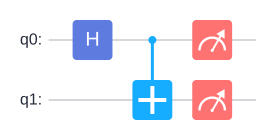

In [3]:
circ.svg()

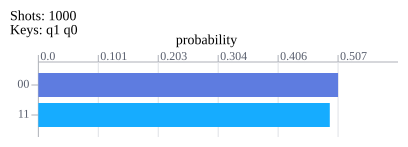

In [4]:
res.svg()

## 遇到问题？

| 现象 | 处理 |
|---|---|
| `No module named 'mindquantum'` | Jupyter 用的 Python 与安装时不同。在同一个环境中运行 `python -m pip install -r requirements.txt` |
| 训练时报 `compiled using NumPy 1.x` | 安装 `numpy<2`（`requirements.txt` 已固定版本） |
| Windows 上装不上 `openfermionpyscf` | 只影响实验 C 的 VQE 作业，可以改用 MyBinder 在线环境 |

下一步：打开 `01.编程基础.ipynb`。